# Fetal Health Classification: Exploratory Data Analysis & Baseline Model

## 1. Introduction and Project Overview
This Jupyter notebook contains the Exploratory Data Analysis (EDA), data cleaning, feature engineering, and baseline machine learning model for the Fetal Health Capstone Project. The dataset contains features extracted from Cardiotocogram (CTG) exams, classified by expert obstetricians into three fetal health classes:
- 1: Normal
- 2: Suspect
- 3: Pathological

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure display settings
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

# Load dataset
df = pd.read_csv('fetal/fetal_health.csv')
print('Dataset shape:', df.shape)
df.head()

Dataset shape: (2126, 22)


,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,mean_value_of_long_term_variability,histogram_width,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,2.4,64.0,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,10.4,130.0,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,13.4,130.0,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,23.0,117.0,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,19.9,117.0,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


## 2. Data Cleaning & Hygiene
Let's inspect missing values, duplicates, and basic data types.

In [5]:
print(df.info())
print('\nMissing values:\n', df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())

# Drop duplicates if any
df = df.drop_duplicates().reset_index(drop=True)
print('Dataset shape after removing duplicates:', df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 22 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   baseline value                                          2126 non-null   float64
 1   accelerations                                           2126 non-null   float64
 2   fetal_movement                                          2126 non-null   float64
 3   uterine_contractions                                    2126 non-null   float64
 4   light_decelerations                                     2126 non-null   float64
 5   severe_decelerations                                    2126 non-null   float64
 6   prolongued_decelerations                                2126 non-null   float64
 7   abnormal_short_term_variability                         2126 non-null   float64
 8   mean_value_of_short_term_variability             

## 3. Outlier Analysis
Let's analyze outliers using boxplots for key continuous features.

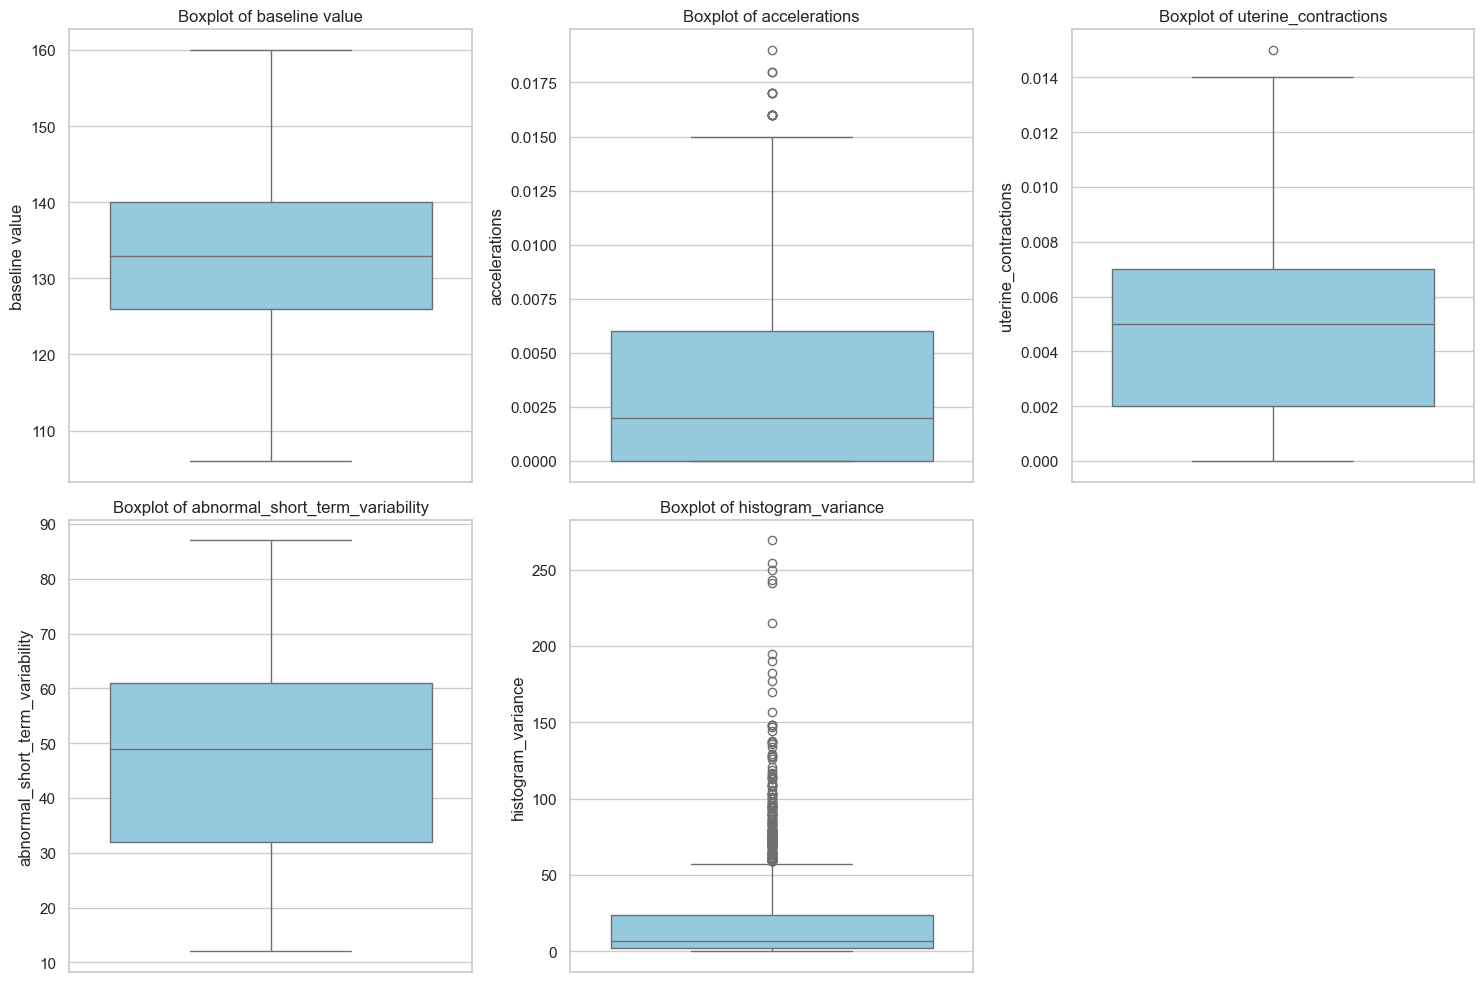

In [6]:
plt.figure(figsize=(15, 10))
features_to_plot = ['baseline value', 'accelerations', 'uterine_contractions', 'abnormal_short_term_variability', 'histogram_variance']
for i, col in enumerate(features_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col], color='skyblue')
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

## 4. Exploratory Data Analysis (EDA) & Visualizations
### Target Variable Distribution

C:\Users\smisra\AppData\Local\Temp\ipykernel_26192\2241691697.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='fetal_health', data=df, palette='Set2')


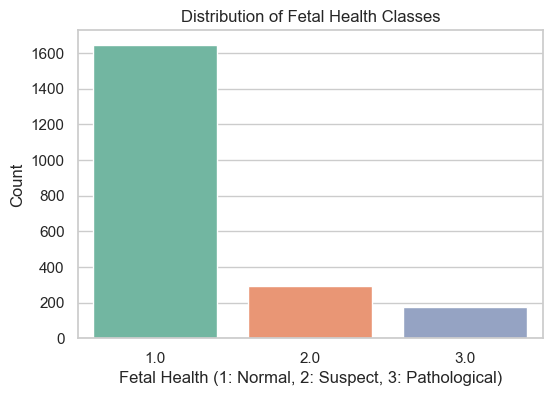

fetal_health
1.0    77.898722
2.0    13.819214
3.0     8.282063
Name: proportion, dtype: float64


In [7]:
plt.figure(figsize=(6, 4))
sns.countplot(x='fetal_health', data=df, palette='Set2')
plt.title('Distribution of Fetal Health Classes')
plt.xlabel('Fetal Health (1: Normal, 2: Suspect, 3: Pathological)')
plt.ylabel('Count')
plt.show()
print(df['fetal_health'].value_counts(normalize=True) * 100)

### Correlation Heatmap

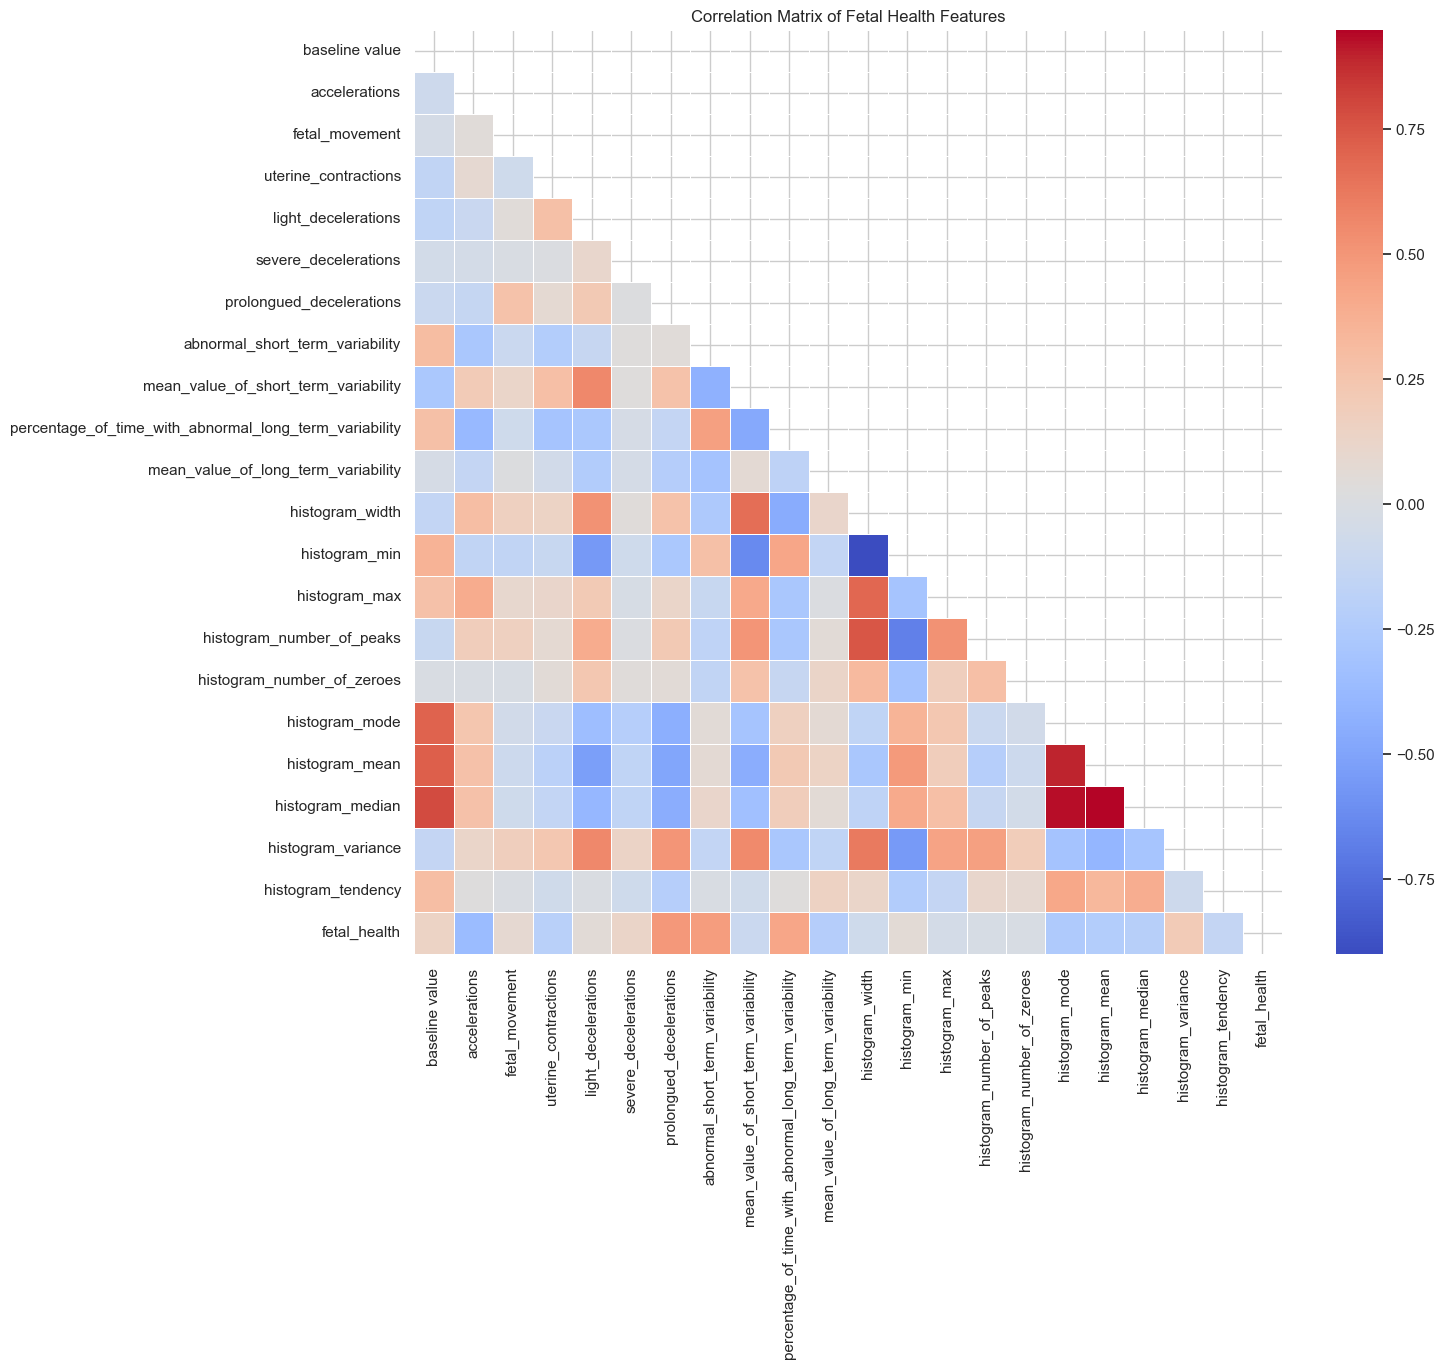

In [8]:
plt.figure(figsize=(14, 12))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=False, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix of Fetal Health Features')
plt.show()

## 5. Feature Engineering
Let's create new informative features such as contraction-acceleration ratios and variability indices.

In [9]:
# Feature engineering
df['contraction_acceleration_ratio'] = df['uterine_contractions'] / (df['accelerations'] + 1e-5)
df['variability_index'] = df['abnormal_short_term_variability'] * df['mean_value_of_short_term_variability']
print(df[['contraction_acceleration_ratio', 'variability_index', 'fetal_health']].head())

   contraction_acceleration_ratio  variability_index  fetal_health
0                        0.000000               36.5           2.0
1                        0.998336               35.7           1.0
2                        2.657807               33.6           1.0
3                        2.657807               38.4           1.0
4                        1.141227               38.4           1.0


## 6. Baseline Machine Learning Model
We will train a baseline Random Forest Classifier and evaluate its performance using classification report and macro F1-score.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

X = df.drop(columns=['fetal_health'])
y = df['fetal_health']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

baseline_model = RandomForestClassifier(random_state=42)
baseline_model.fit(X_train, y_train)

y_pred = baseline_model.predict(X_test)
print('Accuracy:', accuracy_score(y_test, y_pred))
print('\nClassification Report:\n', classification_report(y_test, y_pred))

Accuracy: 0.9456264775413712

Classification Report:
               precision    recall  f1-score   support

         1.0       0.95      0.99      0.97       330
         2.0       0.88      0.72      0.79        58
         3.0       0.97      0.91      0.94        35

    accuracy                           0.95       423
   macro avg       0.93      0.88      0.90       423
weighted avg       0.94      0.95      0.94       423



### Feature Importance of Baseline Model

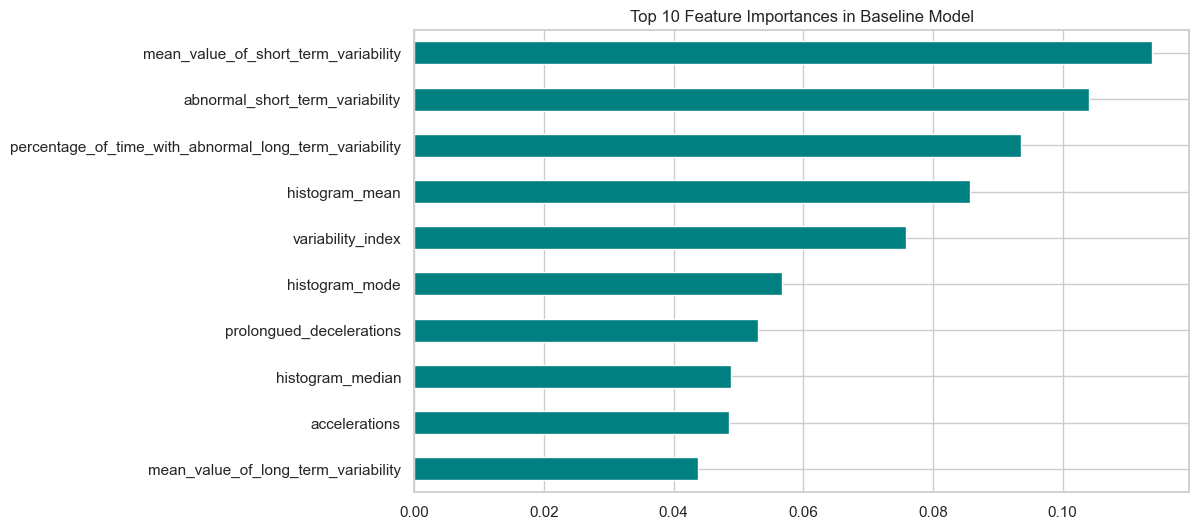

In [11]:
importances = pd.Series(baseline_model.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(10, 6))
importances.head(10).plot(kind='barh', color='teal')
plt.title('Top 10 Feature Importances in Baseline Model')
plt.gca().invert_yaxis()
plt.show()